# Rapport d'étude : méthodes de clustering sur un corpus synthétique

## Introduction générale

Le clustering est une tâche d'apprentissage non supervisé : à partir de mesures décrivant des individus, il cherche à construire des groupes homogènes sans utiliser leurs classes comme information d'apprentissage. Il intervient notamment dans la segmentation de populations, l'exploration de données et la détection de structures ou d'observations atypiques. La qualité d'une partition dépend toutefois de la géométrie des données et des hypothèses propres à chaque algorithme.

Cette étude compare deux familles complémentaires. **K-Means** partitionne directement les observations en un nombre fixé de groupes autour de centroïdes, en minimisant l'inertie intra-cluster. La **classification ascendante hiérarchique (CAH)** construit une hiérarchie de fusions et permet d'examiner les niveaux auxquels les groupes se réunissent; le résultat dépend de la règle de liaison choisie. Un corpus synthétique contrôlé est utile avant l'étude de cas réels : les classes génératrices sont connues, les paramètres sont maîtrisés, et l'on peut donc confronter les partitions estimées à une vérité terrain tout en identifiant les biais géométriques.

L'expérience porte sur 256 individus et deux variables réelles. Deux populations gaussiennes de même effectif sont simulées, avec des centres éloignés mais des dispersions différentes. La graine aléatoire est fixée afin que les résultats soient reproductibles. Les variables sont conservées sur leur échelle d'origine : elles ont la même unité et la différence de variance fait partie de la géométrie que l'étude doit mettre en évidence.

## 1.1 Création du corpus de test

### Question 1.1 - Q.1 : Simulation des deux classes et examen visuel

On génère 128 individus selon $\mathcal{N}((2,2)^T, 2I_2)$ et 128 selon $\mathcal{N}((-4,-4)^T, 6I_2)$. Le tableau récapitulatif décrit les variables simulées; le nuage de points permet d'observer leur séparation et leur dispersion avant toute application d'un algorithme.

,Dimensions
data,"(256, 2)"
true_labels,"(256,)"


X1          X2      
               mean   std  mean   std
classe_reelle                        
0              1.95  1.41  1.93  1.25
1             -3.96  2.46 -4.01  2.47

,Moyenne après standardisation,Écart-type après standardisation
X1,-0.0,1.0
X2,-0.0,1.0


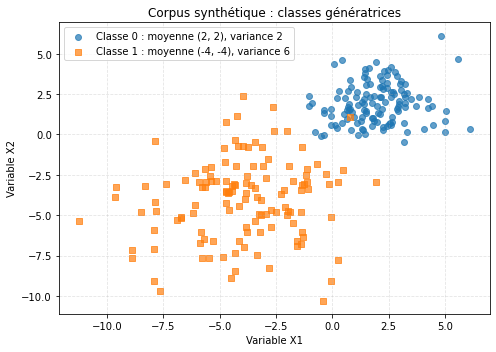

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Simulation reproductible des deux populations gaussiennes.
rng = np.random.default_rng(seed=42)
mu_0, sigma_0 = np.array([2.0, 2.0]), 2.0 * np.eye(2)
mu_1, sigma_1 = np.array([-4.0, -4.0]), 6.0 * np.eye(2)
classe_0 = rng.multivariate_normal(mu_0, sigma_0, size=128)
classe_1 = rng.multivariate_normal(mu_1, sigma_1, size=128)
data = np.concatenate([classe_0, classe_1], axis=0)
true_labels = np.concatenate([np.zeros(128, dtype=int), np.ones(128, dtype=int)])

# Tableau descriptif et contrôle de standardisation.
df_data = pd.DataFrame(data, columns=["X1", "X2"])
df_data["classe_reelle"] = true_labels
display(pd.DataFrame({"Dimensions": [data.shape, true_labels.shape]}, index=["data", "true_labels"]))
display(df_data.groupby("classe_reelle")[["X1", "X2"]].agg(["mean", "std"]).round(2))
data_standardisee = StandardScaler().fit_transform(data)
table_standardisation = pd.DataFrame({
    "Moyenne après standardisation": data_standardisee.mean(axis=0),
    "Écart-type après standardisation": data_standardisee.std(axis=0),
}, index=["X1", "X2"])
display(table_standardisation.round(4))

# Visualisation de la vérité terrain.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(classe_0[:, 0], classe_0[:, 1], color="tab:blue", marker="o", alpha=0.7, label="Classe 0 : moyenne (2, 2), variance 2")
ax.scatter(classe_1[:, 0], classe_1[:, 1], color="tab:orange", marker="s", alpha=0.7, label="Classe 1 : moyenne (-4, -4), variance 6")
ax.set(title="Corpus synthétique : classes génératrices", xlabel="Variable X1", ylabel="Variable X2")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()
plt.show()

### Analyse du corpus

Le tableau confirme des effectifs équilibrés et des dispersions nettement différentes : la seconde population est plus étalée autour de son centre. Le nuage montre deux concentrations principales séparées le long de la diagonale, mais avec un chevauchement local dû à la variance plus élevée de la classe 1. Cette structure rend le problème intéressant : les centres sont distincts, tandis que les formes et les tailles des nuages ne sont pas identiques. Une méthode privilégiant des groupes de taille et de forme comparables peut donc scinder la population la plus dispersée.

## 1.2 Méthode de K-Means

### Questions 1.2.1 - Q.1 et Q.2 : Ajustement pour plusieurs valeurs de K

K-Means est ajusté pour $K \in \{2,3,4\}$ avec une initialisation `k-means++`. La table fournit les inerties et les effectifs par cluster. Dans chaque modèle, `labels_` est un vecteur de 256 entiers : pour chaque individu, il indique l'indice du cluster attribué. Ces indices sont des identifiants arbitraires, et non des prédictions de classes 0/1.

In [15]:
# Comparaison des ajustements K-Means pour K=2, 3 et 4.
modeles_kmeans_n1 = {}
resultats_kmeans = []
for k in [2, 3, 4]:
    modele = KMeans(n_clusters=k, n_init=1, init="k-means++", random_state=42)
    modele.fit(data)
    modeles_kmeans_n1[k] = modele
    resultats_kmeans.append({
        "K": k,
        "Inertie": modele.inertia_,
        "Effectifs par cluster": ", ".join(map(str, np.bincount(modele.labels_))),
    })
table_kmeans = pd.DataFrame(resultats_kmeans).set_index("K")
display(table_kmeans.round(2))

,Inertie,Effectifs par cluster
K,,
2,1898.20,"120, 136"
3,1468.14,"68, 134, 54"
4,1090.90,"52, 129, 45, 30"


### Interprétation des partitions K-Means

L'inertie baisse lorsque $K$ augmente, car chaque augmentation du nombre de groupes apporte davantage de centroïdes pour rapprocher les observations. Les effectifs montrent comment la population la plus dispersée peut être répartie entre plusieurs centroïdes. Cette tendance ne suffit pas à conclure qu'un grand $K$ est préférable : K-Means minimise une somme de distances quadratiques et favorise des cellules approximativement convexes autour de centroïdes. Avec les covariances $2I_2$ et $6I_2$, il peut donc subdiviser la classe la plus étalée même si elle provient d'une seule population.

### Questions 1.2.1 - Q.3 et Q.4 : Évaluation visuelle et quantitative pour K=2

On examine la partition à deux groupes, puis on la compare aux classes génératrices à l'aide de l'Adjusted Rand Index (ARI). L'ARI compare les paires d'individus regroupées ou séparées par les deux partitions, et corrige l'accord attendu par hasard; il vaut 1 pour un accord parfait, est proche de 0 pour un accord aléatoire et peut être négatif. Le taux d'erreur est calculé après alignement des deux étiquettes, car leur numérotation n'a pas de sens intrinsèque.

,Mesure,Valeur
0,ARI,0.8784
1,Taux d'erreur après alignement,0.0312


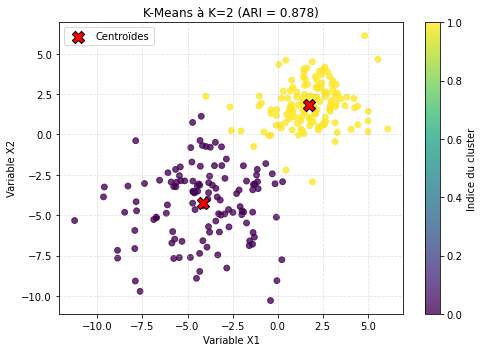

In [16]:
# Évaluation de la partition K-Means à deux groupes.
kmeans_k2_n1 = modeles_kmeans_n1[2]
labels_k2_n1 = kmeans_k2_n1.labels_
ari_kmeans_k2_n1 = adjusted_rand_score(true_labels, labels_k2_n1)
erreur_directe = np.mean(labels_k2_n1 != true_labels)
erreur_inverse = np.mean((1 - labels_k2_n1) != true_labels)
taux_erreur_k2_n1 = min(erreur_directe, erreur_inverse)
resultats_evaluation_k2 = pd.DataFrame({
    "Mesure": ["ARI", "Taux d'erreur après alignement"],
    "Valeur": [ari_kmeans_k2_n1, taux_erreur_k2_n1],
})
display(resultats_evaluation_k2.style.format({"Valeur": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(7, 5))
points = ax.scatter(data[:, 0], data[:, 1], c=labels_k2_n1, cmap="viridis", s=34, alpha=0.78)
ax.scatter(kmeans_k2_n1.cluster_centers_[:, 0], kmeans_k2_n1.cluster_centers_[:, 1],
           c="red", marker="X", s=150, edgecolors="black", label="Centroïdes")
ax.set(title=f"K-Means à K=2 (ARI = {ari_kmeans_k2_n1:.3f})", xlabel="Variable X1", ylabel="Variable X2")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)
fig.colorbar(points, ax=ax, label="Indice du cluster")
fig.tight_layout()
plt.show()

### Interprétation de la partition à deux groupes

Le nuage obtenu sépare les deux concentrations principales, mais la frontière induite par les centroïdes ne suit pas une frontière probabiliste exacte : la classe de variance $6$ déborde davantage dans la zone intermédiaire. Dans cette réalisation, l'ARI est de **0,8784** et le taux d'erreur aligné de **3,12 %**, ce qui traduit une bonne récupération des classes sans perfection. Ces deux mesures sont cohérentes mais ne sont pas interchangeables : l'ARI compare l'ensemble des relations de paires, tandis que le taux d'erreur compte directement les individus après appariement des étiquettes. Le chevauchement intrinsèque interdit de conclure qu'une erreur résiduelle est nécessairement une défaillance d'optimisation.

### Question 1.2.1 - Q.5 : Sensibilité au nombre d'initialisations

Le paramètre `n_init` fixe le nombre d'initialisations indépendantes de K-Means; l'algorithme conserve celle qui produit l'inertie la plus faible. Une initialisation `k-means++` choisit des centres initiaux espacés avec une probabilité liée à leur distance aux centres déjà choisis, ce qui donne souvent un bon départ sans supprimer toute possibilité de minimum local. On compare ici `n_init=1` et `n_init=10` avec la même graine afin d'isoler l'effet du nombre d'essais.

In [17]:
# Comparaison de n_init=1 et n_init=10, à initialisation k-means++ reproductible.
kmeans_k2_n10 = KMeans(n_clusters=2, n_init=10, init="k-means++", random_state=42).fit(data)
ari_kmeans_k2_n10 = adjusted_rand_score(true_labels, kmeans_k2_n10.labels_)
comparaison_n_init = pd.DataFrame({
    "Initialisations": [1, 10],
    "Inertie": [kmeans_k2_n1.inertia_, kmeans_k2_n10.inertia_],
    "ARI": [ari_kmeans_k2_n1, ari_kmeans_k2_n10],
})
display(comparaison_n_init.set_index("Initialisations").round(4))

,Inertie,ARI
Initialisations,,
1,1898.1975,0.8784
10,1898.1975,0.8784


### Interprétation de la comparaison des initialisations

Dans cette exécution, les deux réglages donnent la même inertie (**1898,20**) et le même ARI (**0,8784**). La graine fixe et `k-means++` ont fourni ici un départ efficace dès le premier essai, d'où l'absence de gain observé avec dix essais. Ce résultat ne signifie pas que `n_init` est inutile en général : sans la même initialisation, ou sur une géométrie plus difficile, les solutions peuvent diverger. Augmenter `n_init` améliore la robustesse pratique au prix d'un temps de calcul supplémentaire.

## 1.2.2 Choix du nombre optimal de clusters

### Questions 1.2.2 - Q.1 à Q.4 : Inertie, silhouettes et sélection de K

Les modèles sont ajustés pour $K \in \{2,3,4,5,6\}$. L'inertie mesure la dispersion intra-cluster et ne peut qu'augmenter ou rester stable quand le nombre de clusters diminue; la méthode du coude recherche un ralentissement de son amélioration. La largeur de silhouette est calculée pour chacun des 256 individus, puis résumée par son minimum, sa médiane et son maximum; la silhouette moyenne évalue simultanément cohésion et séparation. Ces critères sont complémentaires et doivent être interprétés au regard du fait que les données proviennent de deux populations.

,Inertie,Silhouette moyenne,Silhouette min. individuelle,Silhouette médiane,Silhouette max. individuelle
K,,,,,
2,1898.1975,0.6094,-0.0549,0.6431,0.7985
3,1419.7941,0.4971,-0.1395,0.5292,0.7718
4,1090.9039,0.5182,-0.0551,0.5337,0.7851
5,908.0095,0.3494,-0.0668,0.3770,0.6068
6,761.4679,0.3431,-0.0428,0.3820,0.6260


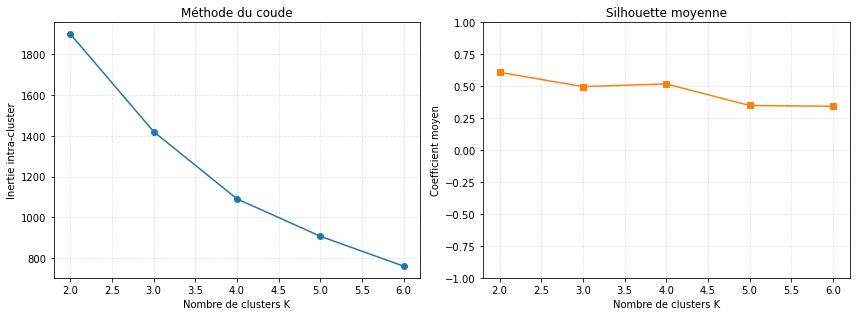

In [18]:
valeurs_k = [2, 3, 4, 5, 6]
inerties = []
silhouettes_moyennes = []
largeurs_silhouette = {}
resume_selection_k = []

for k in valeurs_k:
    modele = KMeans(n_clusters=k, n_init=10, init="k-means++", random_state=42)
    labels = modele.fit_predict(data)
    largeurs = silhouette_samples(data, labels)
    score_moyen = silhouette_score(data, labels)
    inerties.append(modele.inertia_)
    silhouettes_moyennes.append(score_moyen)
    largeurs_silhouette[k] = largeurs
    resume_selection_k.append({
        "K": k,
        "Inertie": modele.inertia_,
        "Silhouette moyenne": score_moyen,
        "Silhouette min. individuelle": largeurs.min(),
        "Silhouette médiane": np.median(largeurs),
        "Silhouette max. individuelle": largeurs.max(),
    })

display(pd.DataFrame(resume_selection_k).set_index("K").round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(valeurs_k, inerties, marker="o", color="tab:blue")
axes[0].set(title="Méthode du coude", xlabel="Nombre de clusters K", ylabel="Inertie intra-cluster")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[1].plot(valeurs_k, silhouettes_moyennes, marker="s", color="tab:orange")
axes[1].set(title="Silhouette moyenne", xlabel="Nombre de clusters K", ylabel="Coefficient moyen")
axes[1].set_ylim(-1, 1)
axes[1].grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()
plt.show()

### Interprétation des critères de sélection

La silhouette moyenne atteint son maximum à **K=2 (0,6094)**, ce qui correspond à la structure génératrice connue. Elle baisse à K=3 (0,4971), remonte légèrement à K=4 (0,5182), puis diminue à K=5 et K=6; le regain à K=4 reflète une subdivision locale qui peut améliorer la compacité sans représenter une classe réelle supplémentaire. Les largeurs négatives indiquent quelques individus plus proches, en moyenne, d'un groupe voisin que de leur groupe attribué, signe du chevauchement observé dans le nuage.

L'inertie décroît régulièrement et présente un ralentissement plutôt qu'un coude parfaitement net : à elle seule, elle ne désigne donc pas une valeur unique. La convergence des indices de silhouette, de l'interprétation de la courbe et de la connaissance expérimentale conduit à retenir **K=2**. En pratique, la vérité terrain ne serait pas disponible; la décision devrait alors rester prudente et être confrontée à la stabilité des partitions et au sens métier.

## 1.3 Classification Ascendante Hiérarchique

### Questions 1.3 - Q.1 et Q.2 : Matrice de liaison et dendrogramme complet

La CAH commence par fusionner les individus les plus proches et répète l'opération jusqu'à réunir toutes les observations. Pour le lien complet, la distance entre deux groupes est la plus grande distance entre leurs membres; cette règle tend à limiter le diamètre des groupes. La matrice de liaison `Z_complete` consigne les fusions, les distances correspondantes et les effectifs agrégés. Le dendrogramme donne une lecture globale des fusions et de leurs sauts de hauteur.

,Indice gauche,Indice droit,Distance de fusion,Effectif fusionné
0,207.0,236.0,0.031,2.0
1,142.0,232.0,0.036,2.0
2,22.0,112.0,0.039,2.0
3,10.0,109.0,0.048,2.0
4,145.0,147.0,0.069,2.0
5,104.0,114.0,0.075,2.0
6,8.0,70.0,0.078,2.0
7,224.0,245.0,0.083,2.0


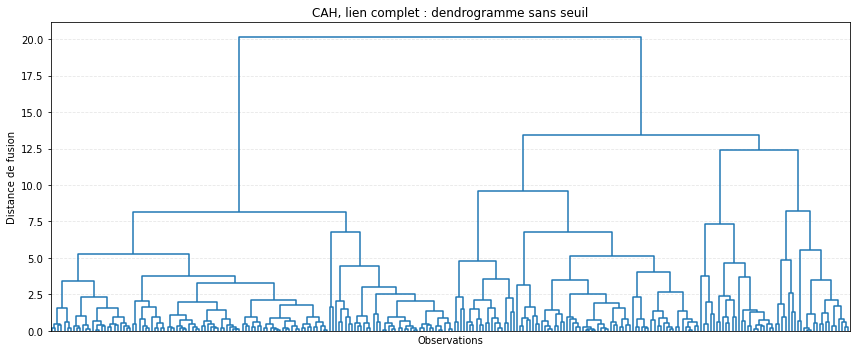

In [19]:
# Matrice de liaison de la CAH avec lien complet et distance euclidienne.
Z_complete = linkage(data, method="complete", metric="euclidean")
display(pd.DataFrame(Z_complete[:8], columns=["Indice gauche", "Indice droit", "Distance de fusion", "Effectif fusionné"]).round(3))

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z_complete, ax=ax, color_threshold=0, no_labels=True)
ax.set(title="CAH, lien complet : dendrogramme sans seuil", xlabel="Observations", ylabel="Distance de fusion")
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

### Interprétation du dendrogramme sans seuil

Les petites hauteurs en bas du dendrogramme correspondent aux fusions d'individus ou de petits groupes très proches. Les fusions tardives se produisent à des distances plus grandes; les sauts de hauteur signalent des regroupements de populations déjà séparées. La matrice montre les étapes initiales, tandis que le dendrogramme complet fait apparaître la structure globale. Le lien complet résiste à l'effet de chaîne du lien simple, mais sa distance maximale le rend sensible aux points extrêmes : un individu éloigné peut retarder la fusion de deux groupes.

### Questions 1.3 - Q.3 et Q.4 : Détermination du seuil et extraction de trois groupes

Le seuil de coupe est calculé automatiquement comme le milieu des deux hauteurs de fusion qui encadrent le passage de trois groupes à deux. On applique ensuite `fcluster` avec le critère de distance. Le tableau donne les effectifs et l'ARI face aux classes génératrices; le dendrogramme matérialise la coupe par une ligne horizontale. L'ARI constitue ici une comparaison descriptive, puisque demander trois clusters revient volontairement à subdiviser l'une des deux populations simulées.

,Effectif
Groupe CAH,
1,129
2,79
3,48


,Seuil de coupe,Nombre de groupes,ARI vs classes génératrices
0,12.9077,3,0.7518


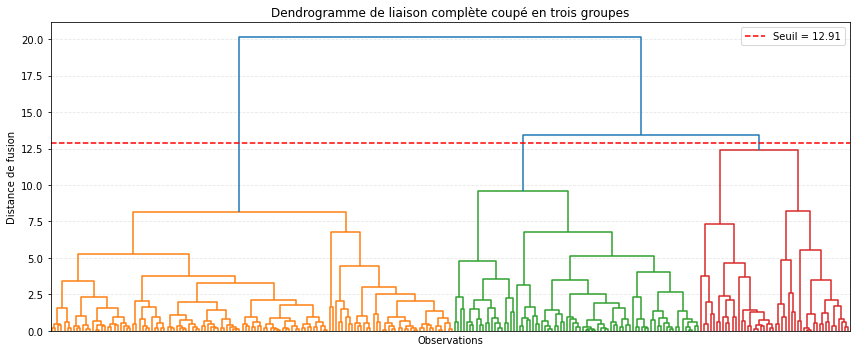

In [20]:
# Coupe du dendrogramme de liaison complète pour obtenir trois groupes.
K_cah = 3
seuil_cah_k3 = (Z_complete[-K_cah, 2] + Z_complete[-(K_cah - 1), 2]) / 2
groupes_cah_k3 = fcluster(Z_complete, t=seuil_cah_k3, criterion="distance")
assert np.unique(groupes_cah_k3).size == K_cah

resume_cah_k3 = pd.DataFrame({
    "Effectif": pd.Series(groupes_cah_k3).value_counts().sort_index(),
})
resume_cah_k3.index.name = "Groupe CAH"
ari_cah_k3 = adjusted_rand_score(true_labels, groupes_cah_k3)
display(resume_cah_k3)
display(pd.DataFrame({"Seuil de coupe": [seuil_cah_k3], "Nombre de groupes": [K_cah], "ARI vs classes génératrices": [ari_cah_k3]}).round(4))

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z_complete, ax=ax, color_threshold=seuil_cah_k3, no_labels=True)
ax.axhline(y=seuil_cah_k3, color="red", linestyle="--", linewidth=1.5, label=f"Seuil = {seuil_cah_k3:.2f}")
ax.set(title="Dendrogramme de liaison complète coupé en trois groupes", xlabel="Observations", ylabel="Distance de fusion")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

### Interprétation du seuil et de la partition à trois groupes

Le seuil obtenu est d'environ **12,91** et extrait bien trois groupes, de tailles **129, 79 et 48**. La partition en trois groupes scinde donc la population plus dispersée en deux sous-ensembles, alors que le nombre de groupes demandé est supérieur au nombre de populations génératrices. L'ARI de **0,7518** reste élevé, mais il ne doit pas être lu comme une erreur de l'algorithme : il pénalise une partition volontairement plus fine que la vérité terrain. Le saut de fusion autour du seuil matérialise précisément le compromis entre conserver les deux grandes populations et détailler leur structure interne.

### Question 1.3 - Q.5 : Visualisation spatiale des groupes CAH

La visualisation reporte les trois étiquettes issues de la coupe sur le plan des variables. Elle permet de vérifier où la CAH a scindé la population la plus étalée, information que le seul dendrogramme, qui ordonne les feuilles pour la lisibilité, ne fournit pas directement.

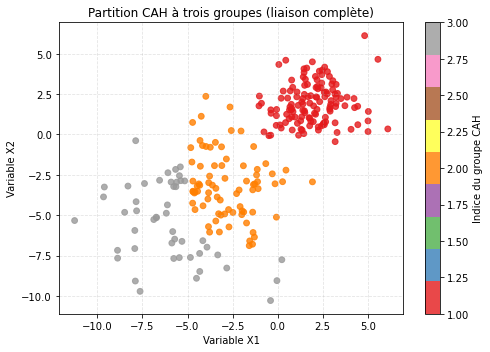

In [21]:
# Projection des trois groupes CAH dans l'espace des variables.
fig, ax = plt.subplots(figsize=(7, 5))
points = ax.scatter(data[:, 0], data[:, 1], c=groupes_cah_k3, cmap="Set1", s=34, alpha=0.8)
ax.set(title="Partition CAH à trois groupes (liaison complète)", xlabel="Variable X1", ylabel="Variable X2")
ax.grid(True, linestyle="--", alpha=0.35)
fig.colorbar(points, ax=ax, label="Indice du groupe CAH")
fig.tight_layout()
plt.show()

### Interprétation de la géométrie des groupes

Le nuage coloré montre deux zones principales, dont la zone la plus dispersée est partagée en deux groupes; la coupure complète cherche à éviter les fusions qui imposeraient un grand diamètre maximal. Les groupes obtenus sont donc plus compacts que ceux que produirait une liaison simple, mais ils ne correspondent pas tous à des populations distinctes au sens génératif. Cette figure rappelle qu'une partition dépend de la résolution choisie : le nombre de groupes est une décision de modélisation, pas une propriété révélée sans ambiguïté par les données.

### Question 1.3 - Q.6 : Comparaison des quatre méthodes de liaison pour K=2

On compare `single`, `complete`, `average` et `ward` avec une coupe en deux groupes. Le lien simple définit la distance entre deux groupes par la paire la plus proche; il peut produire un effet de chaîne. Le lien complet utilise la paire la plus éloignée et tend à favoriser des groupes compacts. Le lien moyen agrège les distances entre paires, tandis que Ward choisit la fusion qui augmente le moins l'inertie intra-groupe; il est particulièrement adapté aux groupes approximativement sphériques. Les quatre dendrogrammes sont présentés ensemble, et leurs partitions sont évaluées par ARI face aux classes génératrices puis comparées à K-Means.

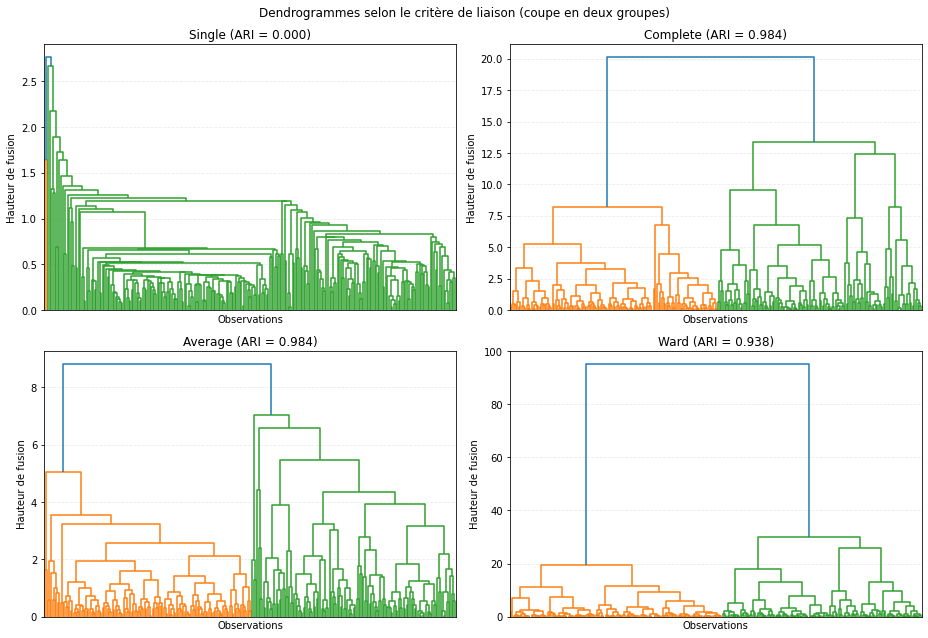

,ARI
Méthode,
single,0.0001
complete,0.9844
average,0.9844
ward,0.9382
K-Means (n_init=1),0.8784
K-Means (n_init=10),0.8784


In [22]:
methodes_liaison = ["single", "complete", "average", "ward"]
resultats_ari_cah = []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for methode, ax in zip(methodes_liaison, axes.ravel()):
    matrice_liaison = linkage(data, method=methode, metric="euclidean")
    labels_cah_k2 = fcluster(matrice_liaison, t=2, criterion="maxclust")
    ari_methode = adjusted_rand_score(true_labels, labels_cah_k2)
    resultats_ari_cah.append({"Méthode": methode, "ARI": ari_methode})

    seuil_visuel = (matrice_liaison[-2, 2] + matrice_liaison[-1, 2]) / 2
    dendrogram(matrice_liaison, ax=ax, no_labels=True, color_threshold=seuil_visuel)
    ax.set(title=f"{methode.capitalize()} (ARI = {ari_methode:.3f})", xlabel="Observations", ylabel="Hauteur de fusion")
    ax.grid(axis="y", linestyle="--", alpha=0.25)

fig.suptitle("Dendrogrammes selon le critère de liaison (coupe en deux groupes)")
fig.tight_layout()
plt.show()

comparaison_ari = pd.DataFrame(resultats_ari_cah)
comparaison_ari = pd.concat([
    comparaison_ari,
    pd.DataFrame([
        {"Méthode": "K-Means (n_init=1)", "ARI": ari_kmeans_k2_n1},
        {"Méthode": "K-Means (n_init=10)", "ARI": ari_kmeans_k2_n10},
    ]),
], ignore_index=True)
display(comparaison_ari.set_index("Méthode").round(4))

### Interprétation comparative des dendrogrammes et des ARI

Le lien simple présente l'effet de chaîne : quelques points intermédiaires peuvent relier progressivement des observations éloignées, d'où une partition très déséquilibrée et un ARI de **0,0001**. Le lien complet et le lien moyen isolent nettement les deux populations et atteignent chacun **0,9844**. Ward obtient **0,9382** : sa préférence pour des groupes compacts et de variance limitée est globalement pertinente, mais la population la plus étalée s'accorde moins parfaitement à cette hypothèse. K-Means atteint **0,8784** avec les deux valeurs de `n_init`; la différence avec les meilleures CAH traduit ici l'avantage de la séparation hiérarchique face aux dispersions inégales, pas une supériorité universelle. Les hauteurs ne sont pas directement comparables entre méthodes, car chacune définit sa propre distance inter-groupes.

## Conclusion de la Partie 1

Sur ce corpus synthétique, K-Means fournit une partition simple et interprétable, mais son objectif quadratique et sa préférence pour des groupes de compacité comparable le rendent sensible aux variances inégales. La silhouette et la connaissance des classes génératrices soutiennent K=2; l'égalité des résultats pour `n_init=1` et `n_init=10` tient à cette réalisation et à l'initialisation `k-means++`, sans garantir une invariance générale.

La CAH apporte une lecture multi-échelle grâce au dendrogramme et permet de choisir après coup le nombre de groupes. Toutefois, sa partition dépend fortement de la liaison : le lien simple échoue ici par effet de chaîne, tandis que les liens complet et moyen récupèrent presque parfaitement les classes; Ward donne un résultat intermédiaire. Les résultats rappellent qu'une méthode ne se choisit pas seulement par son score : la géométrie des données, les hypothèses du critère, la stabilité et l'objectif de l'étude sont déterminants. Sur des données réelles sans vérité terrain, il faudrait compléter ces diagnostics par une analyse de stabilité, des connaissances métier et une validation externe lorsque celle-ci est disponible.

# 2. Application dans un contexte de données réelles

## Introduction de la Partie 2

La Partie 1 utilisait un corpus synthétique dont les classes génératrices étaient connues. Dans une application réelle, les groupes ne sont généralement pas étiquetés à l'avance : la validation repose donc surtout sur la cohérence interne, la stabilité des partitions, leur interprétabilité et des connaissances du domaine. Les données réelles introduisent aussi des choix de préparation importants. Les variables doivent être mises à une échelle comparable lorsque leur amplitude diffère, et les résultats doivent pouvoir être relus dans leur contexte visuel ou physique.

Deux applications sont étudiées. La première réduit le nombre de couleurs d'une image en regroupant les pixels dans l'espace RGB, ce qui met en évidence le compromis entre compression et fidélité perceptuelle. La seconde regroupe des villes à partir de leurs profils mensuels de température. Elle comporte douze dimensions actives et des coordonnées géographiques conservées séparément pour interpréter les groupes sur une carte. Les coordonnées ne sont pas utilisées pour former les clusters, afin que la classification repose sur le climat observé plutôt que sur la seule proximité spatiale.

## 2.1 Réduction de couleurs par K-Means

### Question 2.1 - Q.1 : Charger l'image et réduire sa palette

L'image `visage.bmp` est lue en `float32`, puis convertie d'un tableau de pixels en une matrice où chaque ligne représente un pixel RGB. K-Means associe chaque pixel à un centroïde de couleur; la reconstruction remplace la couleur initiale par celle du centroïde et redonne à la matrice sa forme image d'origine. Le contrôle de plage des valeurs évite une mise à l'échelle d'affichage incorrecte selon la manière dont le fichier BMP est décodé.

Dimensions de l'image : H=256, L=256, canaux=3; pixels=65,536
Plage RGB lue : [0.000, 255.000]


,Inertie (erreur de quantification),Bits/pixel théoriques,Compression palette (24 bits / log2(K))
K couleurs,,,
2,145163824.0,1.0,24.0
4,72537896.0,2.0,12.0
8,30439550.0,3.0,8.0
16,14913247.0,4.0,6.0
32,7352674.5,5.0,4.8


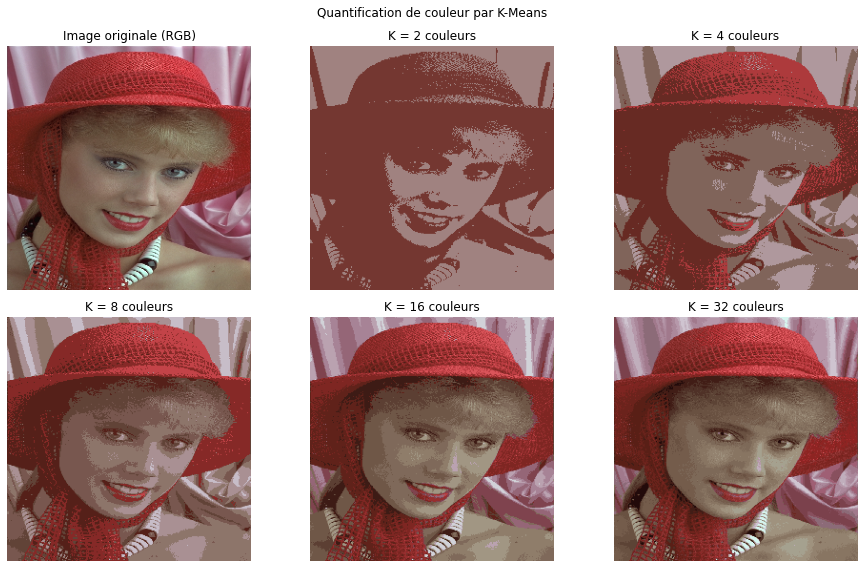

In [25]:
import matplotlib.image as mpimg

# Lecture RGB et remise à plat en une ligne par pixel.
img = np.float32(mpimg.imread("visage.bmp"))
if img.ndim != 3 or img.shape[2] != 3:
    raise ValueError(f"L'image doit avoir exactement trois canaux RGB; forme reçue : {img.shape}")
hauteur, largeur, canaux = img.shape
pixels_rgb = np.reshape(img, (hauteur * largeur, canaux))

# imread peut fournir soit des intensités 0-255, soit des valeurs normalisées 0-1.
echelle_rgb = 255.0 if pixels_rgb.max() > 1.0 else 1.0
valeurs_k_image = [2, 4, 8, 16, 32]
reconstructions = {}
resultats_image = []
for k in valeurs_k_image:
    modele_image = KMeans(n_clusters=k, n_init=10, init="k-means++", random_state=42)
    labels_pixels = modele_image.fit_predict(pixels_rgb)
    image_codee = modele_image.cluster_centers_[labels_pixels]
    reconstructions[k] = np.reshape(image_codee, (hauteur, largeur, canaux))
    resultats_image.append({
        "K couleurs": k,
        "Inertie (erreur de quantification)": modele_image.inertia_,
        "Bits/pixel théoriques": np.log2(k),
        "Compression palette (24 bits / log2(K))": 24.0 / np.log2(k),
    })

table_image = pd.DataFrame(resultats_image).set_index("K couleurs")
print(f"Dimensions de l'image : H={hauteur}, L={largeur}, canaux={canaux}; pixels={pixels_rgb.shape[0]:,}")
print(f"Plage RGB lue : [{pixels_rgb.min():.3f}, {pixels_rgb.max():.3f}]")
display(table_image.round(2))

# Affichage côte à côte de l'original et des cinq palettes réduites.
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.ravel()
axes[0].imshow(img / echelle_rgb)
axes[0].set_title("Image originale (RGB)")
axes[0].axis("off")
for ax, k in zip(axes[1:], valeurs_k_image):
    ax.imshow(reconstructions[k] / echelle_rgb)
    ax.set_title(f"K = {k} couleurs")
    ax.axis("off")
fig.suptitle("Quantification de couleur par K-Means")
fig.tight_layout()
plt.show()

### Question 2.1 - Q.2 : Comparer la qualité visuelle et le coût de représentation

Le tableau rapproche l'inertie, qui mesure l'erreur quadratique de quantification RGB, du coût théorique de codage d'un indice de palette. Il s'agit d'une borne simplifiée : une image effectivement compressée doit aussi stocker la palette et les indices des pixels, et les gains dépendent du format de fichier. La figure compare l'original aux reconstructions pour les cinq tailles de palette.

**Interprétation.** À $K=2$ et $K=4$, le visage et l'arrière-plan sont ramenés à quelques aplats; les transitions de tons deviennent des bandes visibles, phénomène de postérisation. À $K=8$, les grandes formes sont identifiables mais les ombres et textures restent grossières. Dès $K=16$, les traits du visage, les plis et les dégradés sont mieux conservés; $K=32$ améliore encore les nuances, avec un gain visuel plus modéré au regard du coût supplémentaire. La baisse monotone de l'inertie confirme que plus de centroïdes réduisent l'erreur numérique, mais cette métrique ne mesure pas directement l'importance perceptuelle des détails. Le choix de K dépend donc de l'usage : aperçu fortement compacté ou reproduction visuellement fidèle.

## 2.2 Clustering de données de températures

Le jeu de données rassemble 35 villes françaises et européennes, leurs températures moyennes mensuelles de janvier à décembre et plusieurs variables complémentaires (région, moyenne annuelle, amplitude et coordonnées géographiques). Pour construire les profils climatiques, seules les douze températures mensuelles sont actives. Les coordonnées sont réservées aux cartes et les variables récapitulatives sont exclues afin d'éviter de compter deux fois une information déjà portée par les mois.

### Préparation et choix de l'échelle

**Objectif :** charger et contrôler le jeu de données, extraire les coordonnées pour l'interprétation spatiale et préparer les profils mensuels pour le clustering. Les douze variables sont toutes exprimées en degrés Celsius, mais leurs variances diffèrent selon les mois : l'hiver présente souvent une dispersion géographique plus forte que l'été. Nous retenons donc un centrage-réduction par mois avec `StandardScaler`, afin que chaque mois contribue de façon comparable à la distance euclidienne. Cette décision porte l'attention sur la forme annuelle du profil plutôt que sur les mois les plus dispersés. Elle implique aussi que la classification privilégie des écarts relatifs à la variabilité de chaque mois; une analyse sur les températures brutes répondrait à une autre question, celle de la proximité absolue en degrés.

In [26]:
# Chargement selon le format du fichier et séparation variables actives / variables descriptives.
data_temperature = pd.read_csv("temperatures.csv", sep=";", decimal=".", header=0, index_col=0)
colonnes_mensuelles = [
    "Janvier", "Fevrier", "Mars", "Avril", "Mai", "Juin",
    "Juillet", "Aout", "Septembre", "Octobre", "Novembre", "Decembre",
]
colonnes_inactives = ["Region", "Moyenne", "Amplitude", "Latitude", "Longitude"]
coordonnees = data_temperature[["Longitude", "Latitude"]].copy()
data_temperature_mois = data_temperature.drop(columns=colonnes_inactives)
data_temperature_standardisee = pd.DataFrame(
    StandardScaler().fit_transform(data_temperature_mois),
    index=data_temperature_mois.index,
    columns=colonnes_mensuelles,
)

resume_donnees_climat = pd.DataFrame({
    "Valeur": [len(data_temperature), data_temperature_mois.shape[1], data_temperature_mois.isna().sum().sum()],
}, index=["Nombre de villes", "Variables mensuelles actives", "Valeurs manquantes"])
display(resume_donnees_climat)
display(data_temperature_mois.describe().loc[["mean", "std", "min", "max"]].round(1))
display(data_temperature_standardisee.mean().to_frame("Moyenne standardisée").join(
    data_temperature_standardisee.std().to_frame("Écart-type standardisé")).round(3))

,Valeur
Nombre de villes,35
Variables mensuelles actives,12
Valeurs manquantes,0


,Janvier,Fevrier,Mars,Avril,Mai,Juin,Juillet,Aout,Septembre,Octobre,Novembre,Decembre
mean,1.3,2.2,5.2,9.3,13.9,17.4,19.6,19.0,15.6,11.0,6.1,2.9
std,5.5,5.5,4.9,3.8,3.3,3.3,3.6,3.7,4.1,4.3,4.6,5.0
min,-9.3,-7.9,-3.7,2.9,6.5,9.3,11.1,10.6,7.9,4.5,-1.1,-6.0
max,10.7,11.8,14.1,16.9,20.9,24.5,27.4,27.2,24.3,19.4,14.9,12.0


,Moyenne standardisée,Écart-type standardisé
Janvier,0.0,1.015
Fevrier,0.0,1.015
Mars,-0.0,1.015
Avril,-0.0,1.015
Mai,0.0,1.015
Juin,-0.0,1.015
Juillet,-0.0,1.015
Aout,-0.0,1.015
Septembre,-0.0,1.015
Octobre,0.0,1.015


### Interprétation du chargement et du prétraitement

Le fichier contient bien **35 villes**, douze variables mensuelles et aucune valeur manquante. Les statistiques montrent une dispersion géographique plus forte en hiver qu'au cœur de l'été; standardiser les mois empêche donc janvier ou février de dominer mécaniquement une distance euclidienne. Le choix reste substantiel : les profils transformés expriment les écarts à la moyenne et à la variabilité de chaque mois, non une différence absolue de degrés. Les colonnes de région, moyenne annuelle, amplitude et coordonnées sont gardées pour décrire ou cartographier les groupes, mais ne participent pas à la distance climatique.

### 2.2.1 Classification ascendante hiérarchique

#### Question 2.2.1 - Q.1 et Q.2 : Construire le dendrogramme de Ward et choisir une coupe

Ward fusionne les groupes en minimisant l'augmentation de la somme des carrés intra-cluster; il s'applique ici aux profils mensuels standardisés avec distance euclidienne. Le dendrogramme affiche les noms des villes. Pour étayer le seuil, le tableau calcule les hauteurs de fusion qui encadrent des partitions candidates de 2 à 6 groupes; un grand saut entre deux fusions suggère une séparation hiérarchique. La coupe retenue sera vérifiée avec les profils thermiques et la carte, car un saut statistique ne garantit pas à lui seul une classification géographique ou climatologique pertinente.

,Hauteur basse,Hauteur haute,Saut de fusion,Rapport haute/basse
Groupes conservés,,,,
2,10.579,23.083,12.504,2.182
3,7.758,10.579,2.821,1.364
4,5.687,7.758,2.071,1.364
5,5.080,5.687,0.607,1.119
6,3.568,5.080,1.512,1.424


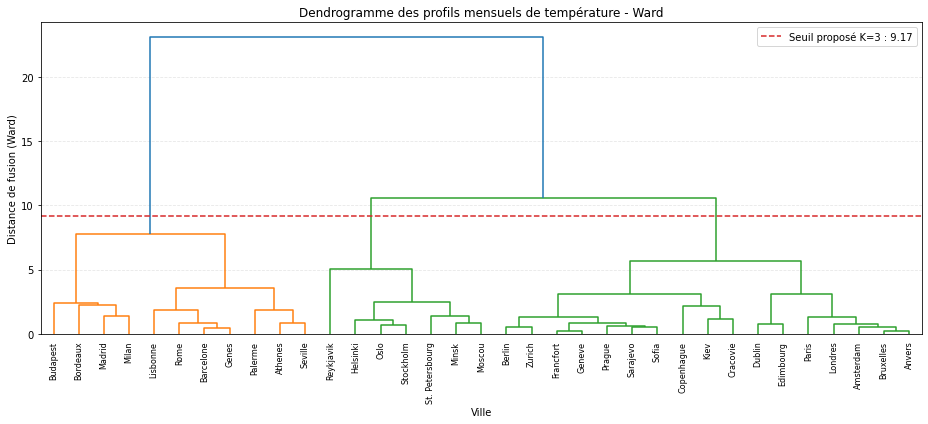

In [28]:
# Ward sur les profils mensuels centrés-réduits et seuil candidat pour K=3.
Z_ward = linkage(data_temperature_standardisee, method="ward", metric="euclidean")
K_cah_ward = 3
hauteur_avant_coupe = Z_ward[-K_cah_ward, 2]
hauteur_fusion_suivante = Z_ward[-(K_cah_ward - 1), 2]
seuil_ward = (hauteur_avant_coupe + hauteur_fusion_suivante) / 2
candidats_coupe = []
for k in range(2, 7):
    basse = Z_ward[-k, 2]
    haute = Z_ward[-(k - 1), 2]
    candidats_coupe.append({
        "Groupes conservés": k,
        "Hauteur basse": basse,
        "Hauteur haute": haute,
        "Saut de fusion": haute - basse,
        "Rapport haute/basse": haute / basse if basse else np.inf,
    })
display(pd.DataFrame(candidats_coupe).set_index("Groupes conservés").round(3))

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(Z_ward, labels=list(data_temperature_mois.index), leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.axhline(seuil_ward, color="tab:red", linestyle="--", linewidth=1.5, label=f"Seuil proposé K={K_cah_ward} : {seuil_ward:.2f}")
ax.set(title="Dendrogramme des profils mensuels de température - Ward", xlabel="Ville", ylabel="Distance de fusion (Ward)")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

#### Interprétation du dendrogramme et justification du seuil

Le dernier saut (de 10,58 à 23,08) favorise nettement une partition en deux ensembles. Pour conserver une lecture plus nuancée des régimes climatiques, une coupe en **trois groupes** est retenue : le saut qui la délimite est de 2,82, supérieur à celui qui encadre K=4 (2,07), et le seuil situé à **9,17** reste sous la fusion suivante à 10,58. Ce compromis doit être validé par les profils moyens et la carte ci-dessous. Ward tend à former des groupes compacts dans l'espace des profils standardisés; cela facilite l'interprétation, mais peut moins bien représenter des structures allongées ou des transitions climatiques graduelles.

#### Question 2.2.1 - Q.3 : Extraire les classes et décrire leurs profils thermiques

La coupe est appliquée avec `fcluster`. Pour chaque groupe, on rapporte l'effectif, les villes, la température annuelle moyenne et l'amplitude moyenne calculées à partir des mois bruts, ainsi que le profil mensuel moyen en degrés Celsius. Les statistiques physiques restent ainsi interprétables malgré l'apprentissage sur des variables standardisées.

,Effectif,Villes,Température annuelle moyenne (°C),Amplitude annuelle moyenne (°C)
Cluster Ward,,,,
1,11,"Athenes, Budapest, Lisbonne, Madrid, Rome, Bar...",15.2,17.1
2,7,"Helsinki, Minsk, Moscou, Oslo, Reykjavik, Stoc...",5.1,22.2
3,17,"Amsterdam, Berlin, Bruxelles, Copenhague, Dubl...",9.2,17.5


,Janvier,Fevrier,Mars,Avril,Mai,Juin,Juillet,Aout,Septembre,Octobre,Novembre,Decembre
Cluster_Ward,,,,,,,,,,,,
1,6.9,8.1,10.7,13.9,17.8,21.4,24.0,23.6,20.8,16.2,11.3,8.0
2,-5.5,-5.0,-1.6,4.1,10.2,14.4,16.6,15.3,10.7,5.4,0.4,-3.2
3,0.5,1.4,4.5,8.4,12.9,16.1,18.0,17.5,14.4,9.9,5.0,2.0


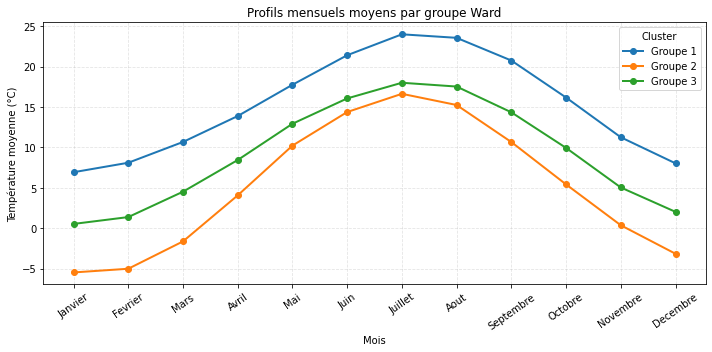

In [30]:
# Attribution de la coupe Ward, puis synthèse descriptive dans l'unité d'origine (°C).
groupes_ward = fcluster(Z_ward, t=seuil_ward, criterion="distance")
assert np.unique(groupes_ward).size == K_cah_ward
profils_ward = data_temperature_mois.assign(Cluster_Ward=groupes_ward)
resume_groupes_ward = []
for groupe, sous_ensemble in profils_ward.groupby("Cluster_Ward"):
    profil_moyen = sous_ensemble[colonnes_mensuelles].mean()
    resume_groupes_ward.append({
        "Cluster Ward": groupe,
        "Effectif": len(sous_ensemble),
        "Villes": ", ".join(sous_ensemble.index),
        "Température annuelle moyenne (°C)": profil_moyen.mean(),
        "Amplitude annuelle moyenne (°C)": (sous_ensemble[colonnes_mensuelles].max(axis=1) - sous_ensemble[colonnes_mensuelles].min(axis=1)).mean(),
    })
resume_groupes_ward = pd.DataFrame(resume_groupes_ward).set_index("Cluster Ward")
profils_mensuels_ward = profils_ward.groupby("Cluster_Ward")[colonnes_mensuelles].mean()
display(resume_groupes_ward.round(1))
display(profils_mensuels_ward.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
for groupe, profil in profils_mensuels_ward.iterrows():
    ax.plot(colonnes_mensuelles, profil.to_numpy(dtype=float), marker="o", linewidth=2, label=f"Groupe {groupe}")
ax.set(title="Profils mensuels moyens par groupe Ward", xlabel="Mois", ylabel="Température moyenne (°C)")
ax.tick_params(axis="x", rotation=35)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(title="Cluster")
fig.tight_layout()
plt.show()

#### Interprétation des effectifs et profils Ward

Le groupe 1 rassemble les profils les plus doux, avec une moyenne annuelle d'environ **15,2 °C** et une amplitude moyenne de **17,1 °C**; le groupe 2 est le plus froid (**5,1 °C**) et présente la plus forte amplitude (**22,2 °C**), caractéristique de climats à saisonnalité marquée. Le groupe 3 est intermédiaire (**9,2 °C**, amplitude **17,5 °C**). Les courbes montrent une saisonnalité commune, avec un maximum en juillet, mais des niveaux et des amplitudes différents. Ces tendances évoquent respectivement des climats méridionaux, froids/continentaux et tempérés, sans prétendre à une classification météorologique officielle : les frontières sont imposées par l'algorithme et des villes de transition peuvent être regroupées selon leur profil annuel global.

#### Question 2.2.1 - Q.4 : Comparer avec le lien complet et cartographier les villes

On reconstruit une CAH par lien complet sur les mêmes profils mensuels standardisés et l'on extrait trois groupes pour rendre la comparaison avec Ward directe. La carte place longitude en abscisse et latitude en ordonnée; les couleurs sont des catégories distinctes indiquées par une légende, et chaque ville est annotée. La géographie sert ici à interpréter les classes, non à les construire.

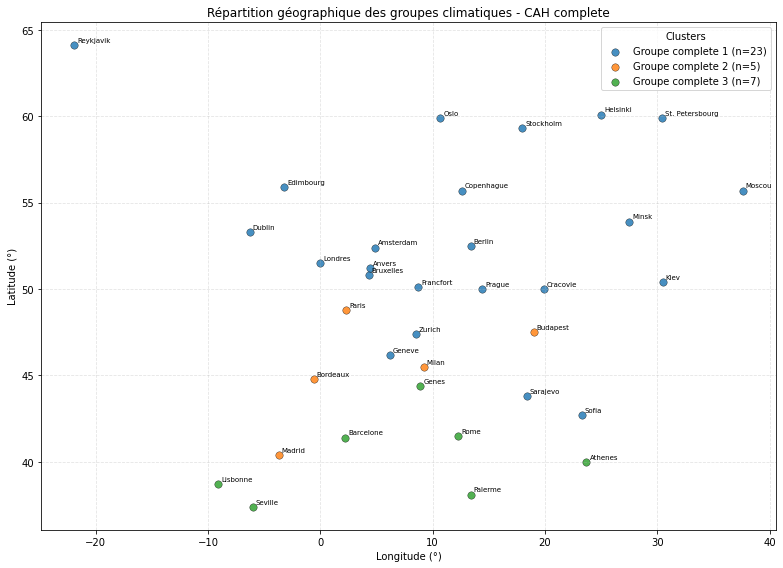

,Villes du groupe
Cluster complete,
1,"Amsterdam, Berlin, Bruxelles, Copenhague, Dubl..."
2,"Budapest, Madrid, Paris, Bordeaux, Milan"
3,"Athenes, Lisbonne, Rome, Barcelone, Genes, Pal..."


In [32]:
# Deuxième CAH : lien complet, coupé en trois classes pour la comparaison spatiale.
Z_complete_temperature = linkage(data_temperature_standardisee, method="complete", metric="euclidean")
groupes_complete = fcluster(Z_complete_temperature, t=K_cah_ward, criterion="maxclust")
assert np.unique(groupes_complete).size == K_cah_ward

fig, ax = plt.subplots(figsize=(11, 8))
for groupe in sorted(np.unique(groupes_complete)):
    masque = groupes_complete == groupe
    ax.scatter(
        coordonnees.loc[masque, "Longitude"],
        coordonnees.loc[masque, "Latitude"],
        s=55, alpha=0.82, edgecolors="black", linewidths=0.4,
        label=f"Groupe complete {groupe} (n={masque.sum()})",
    )
for ville, position in coordonnees.iterrows():
    ax.annotate(ville, (position["Longitude"], position["Latitude"]),
                xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.set(title="Répartition géographique des groupes climatiques - CAH complete",
       xlabel="Longitude (°)", ylabel="Latitude (°)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(title="Clusters", loc="best")
fig.tight_layout()
plt.show()

composition_complete = pd.DataFrame({"Cluster complete": groupes_complete}, index=data_temperature_mois.index)
villes_par_complete = [
    {"Cluster complete": groupe, "Villes du groupe": ", ".join(composition_complete.index[composition_complete["Cluster complete"] == groupe])}
    for groupe in sorted(composition_complete["Cluster complete"].unique())
]
display(pd.DataFrame(villes_par_complete).set_index("Cluster complete"))

#### Interprétation de la carte CAH par lien complet

La carte met en évidence un groupe méridional (notamment Athènes, Lisbonne, Madrid, Séville, Palerme et Barcelone), tandis qu'un grand groupe rassemble les villes du nord et une partie de l'Europe centrale. Le groupe intermédiaire est plus restreint et réunit des villes de transition. La cohérence spatiale générale est donc réelle, surtout au sud, mais les frontières ne suivent pas strictement les régions : le lien complet se base uniquement sur les distances entre profils standardisés, et non sur les coordonnées. Des villes à latitude voisine peuvent ainsi se séparer par leurs hivers ou amplitudes, tandis que des villes éloignées peuvent partager un profil saisonnier.

## 2.3 Méthode des K-Means

### Questions 2.3 - Q.1 et Q.2 : Inertie et choix du nombre de groupes

K-Means est ajusté pour $K=1,\ldots,8$ sur les mêmes douze variables standardisées que la CAH. La silhouette n'est définie qu'à partir de deux clusters; elle complète la règle du coude mais ne remplace pas l'interprétation de l'inertie. La baisse de l'inertie est attendue à chaque ajout de centroïde; le choix de K repose sur le ralentissement des gains et sur la lisibilité des profils, sans vérité terrain climatique connue.

,Inertie,Silhouette moyenne
K,,
1,420.000,NaN
2,149.423,0.558
3,86.694,0.485
4,65.177,0.439
5,49.930,0.438
6,37.948,0.420
7,31.582,0.399
8,27.872,0.368


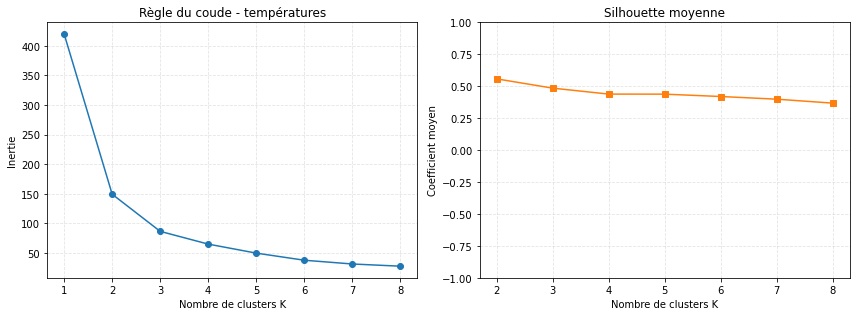

In [33]:
valeurs_k_climat = list(range(1, 9))
inerties_climat = []
silhouettes_climat = []
modeles_kmeans_climat = {}
for k in valeurs_k_climat:
    modele = KMeans(n_clusters=k, n_init=20, init="k-means++", random_state=42)
    labels = modele.fit_predict(data_temperature_standardisee)
    modeles_kmeans_climat[k] = modele
    inerties_climat.append(modele.inertia_)
    silhouettes_climat.append(silhouette_score(data_temperature_standardisee, labels) if k >= 2 else np.nan)

table_criteres_climat = pd.DataFrame({
    "Inertie": inerties_climat,
    "Silhouette moyenne": silhouettes_climat,
}, index=valeurs_k_climat)
table_criteres_climat.index.name = "K"
display(table_criteres_climat.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(valeurs_k_climat, inerties_climat, marker="o", color="tab:blue")
axes[0].set(title="Règle du coude - températures", xlabel="Nombre de clusters K", ylabel="Inertie")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[1].plot(valeurs_k_climat[1:], silhouettes_climat[1:], marker="s", color="tab:orange")
axes[1].set(title="Silhouette moyenne", xlabel="Nombre de clusters K", ylabel="Coefficient moyen")
axes[1].set_ylim(-1, 1)
axes[1].set_xticks(valeurs_k_climat[1:])
axes[1].grid(True, linestyle="--", alpha=0.35)
fig.tight_layout()
plt.show()

#### Interprétation du coude et choix de K

L'inertie passe de **420,0** à K=1 à **86,7** à K=3, puis les diminutions deviennent plus progressives; le coude est donc situé autour de **K=3**. La silhouette maximale est toutefois obtenue à K=2 (**0,558**) et décroît ensuite. Ce désaccord est informatif : deux groupes décrivent une séparation forte entre profils, tandis que trois groupes offrent une segmentation plus détaillée au prix d'une cohésion moyenne moindre. Pour la suite, **K-Means est retenu à K=3** afin de comparer trois régimes climatiques aux partitions CAH déjà établies à trois groupes. Ce choix opérationnel ne constitue pas une vérité objective; une application décisionnelle pourrait préférer K=2 si la simplicité était prioritaire.

### Question 2.3 - Q.3 : Cartographier et interpréter la partition K-Means

On reporte les groupes K-Means de K=3 sur les coordonnées géographiques, qui n'ont pas servi à l'ajustement. Une légende catégorielle explicite et les noms de villes facilitent l'inspection de la cohérence spatiale; les annotations peuvent se chevaucher dans les zones urbaines denses.

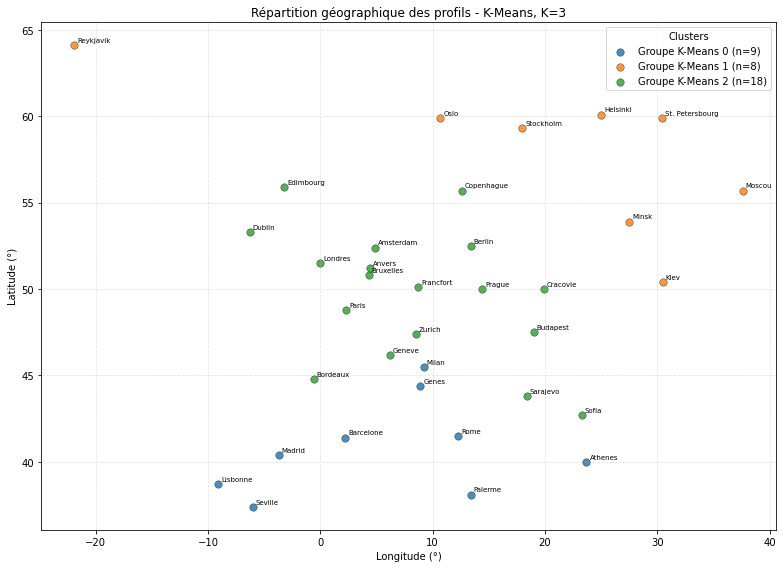

,Villes du groupe
Cluster K-Means,
0,"Athenes, Lisbonne, Madrid, Rome, Barcelone, Ge..."
1,"Helsinki, Kiev, Minsk, Moscou, Oslo, Reykjavik..."
2,"Amsterdam, Berlin, Bruxelles, Budapest, Copenh..."


In [34]:
# Partition finale K-Means pour K=3 et carte annotée.
k_optimal_climat = 3
kmeans_climat_optimal = modeles_kmeans_climat[k_optimal_climat]
groupes_kmeans_climat = kmeans_climat_optimal.labels_

fig, ax = plt.subplots(figsize=(11, 8))
for groupe in sorted(np.unique(groupes_kmeans_climat)):
    masque = groupes_kmeans_climat == groupe
    ax.scatter(
        coordonnees.loc[masque, "Longitude"],
        coordonnees.loc[masque, "Latitude"],
        s=55, alpha=0.82, edgecolors="black", linewidths=0.4,
        label=f"Groupe K-Means {groupe} (n={masque.sum()})",
    )
for ville, position in coordonnees.iterrows():
    ax.annotate(ville, (position["Longitude"], position["Latitude"]),
                xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.set(title="Répartition géographique des profils - K-Means, K=3",
       xlabel="Longitude (°)", ylabel="Latitude (°)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(title="Clusters", loc="best")
fig.tight_layout()
plt.show()

composition_kmeans = pd.DataFrame({"Cluster K-Means": groupes_kmeans_climat}, index=data_temperature_mois.index)
villes_par_kmeans = [
    {"Cluster K-Means": groupe, "Villes du groupe": ", ".join(composition_kmeans.index[composition_kmeans["Cluster K-Means"] == groupe])}
    for groupe in sorted(composition_kmeans["Cluster K-Means"].unique())
]
display(pd.DataFrame(villes_par_kmeans).set_index("Cluster K-Means"))

#### Interprétation de la carte K-Means

La carte K-Means sépare globalement un ensemble méridional (notamment les villes méditerranéennes), un ensemble froid/nordique et un ensemble tempéré plus central. La concentration spatiale des deux premiers groupes est visible, tandis que le groupe tempéré s'étend sur une zone plus large. Les exceptions et villes de transition résultent de profils saisonniers proches plutôt que d'une contrainte géographique : l'algorithme n'a reçu que les températures mensuelles. Cette partition est donc utile pour résumer des régimes thermiques, mais elle ne doit pas être interprétée comme une carte administrative ou une classification climatique officielle.

## 2.4 Comparaison des classifications

### Question 2.4 - Q.1 : Comparer Ward, lien complet et K-Means

Les trois méthodes sont comparées à trois groupes sur les mêmes variables standardisées. Les tableaux croisés indiquent les recouvrements entre étiquettes, et l'ARI mesure leur accord en étant invariant à la permutation des numéros de clusters. Pour interpréter les villes qui changent de groupe, les étiquettes de chaque méthode sont d'abord alignées au mieux sur celles de K-Means; les désaccords restants sont ensuite listés avec les numéros originaux et alignés.

In [35]:
from itertools import permutations

# Tableau commun des trois partitions; les noms de villes restent l'index.
labels_comparaison = pd.DataFrame({
    "Ward": groupes_ward,
    "Complete": groupes_complete,
    "K-Means": groupes_kmeans_climat,
}, index=data_temperature_mois.index)

# ARI invariant aux numéros de groupes, et alignement optimal pour comparer ville par ville.
def aligner_sur_reference(reference, labels_a_aligner):
    labels_candidats = sorted(np.unique(labels_a_aligner))
    labels_reference = sorted(np.unique(reference))
    meilleure_correspondance = None
    meilleur_score = -1
    for permutation in permutations(labels_reference):
        correspondance = dict(zip(labels_candidats, permutation))
        labels_alignes = np.array([correspondance[label] for label in labels_a_aligner])
        score = np.sum(labels_alignes == reference)
        if score > meilleur_score:
            meilleure_correspondance = correspondance
            meilleur_score = score
    return np.array([meilleure_correspondance[label] for label in labels_a_aligner])

ward_aligne = aligner_sur_reference(labels_comparaison["K-Means"].to_numpy(), labels_comparaison["Ward"].to_numpy())
complete_aligne = aligner_sur_reference(labels_comparaison["K-Means"].to_numpy(), labels_comparaison["Complete"].to_numpy())
labels_comparaison["Ward aligné"] = ward_aligne
labels_comparaison["Complete aligné"] = complete_aligne

scores_accord = pd.DataFrame({
    "Paire de méthodes": ["Ward / Complete", "Ward / K-Means", "Complete / K-Means"],
    "ARI": [
        adjusted_rand_score(groupes_ward, groupes_complete),
        adjusted_rand_score(groupes_ward, groupes_kmeans_climat),
        adjusted_rand_score(groupes_complete, groupes_kmeans_climat),
    ],
})
display(scores_accord.set_index("Paire de méthodes").round(4))

# Tableaux croisés avec K-Means en référence; les colonnes des deux CAH sont alignées.
display(pd.crosstab(labels_comparaison["K-Means"], labels_comparaison["Ward aligné"]).rename_axis("K-Means / Ward aligné"))
display(pd.crosstab(labels_comparaison["K-Means"], labels_comparaison["Complete aligné"]).rename_axis("K-Means / Complete aligné"))

villes_modifiees = labels_comparaison.loc[
    (labels_comparaison["K-Means"] != labels_comparaison["Ward aligné"])
    | (labels_comparaison["K-Means"] != labels_comparaison["Complete aligné"]),
    ["Ward", "Ward aligné", "Complete", "Complete aligné", "K-Means"],
]
display(villes_modifiees.sort_index())

,ARI
Paire de méthodes,
Ward / Complete,0.4551
Ward / K-Means,0.7339
Complete / K-Means,0.3704


Ward aligné,0,1,2
K-Means / Ward aligné,,,
0,9,0,0
1,0,7,1
2,2,0,16


Complete aligné,0,1,2
K-Means / Complete aligné,,,
0,7,2,0
1,0,0,8
2,0,3,15


,Ward,Ward aligné,Complete,Complete aligné,K-Means
City,,,,,
Bordeaux,1,0,2,1,2
Budapest,1,0,2,1,2
Helsinki,2,1,1,2,1
Kiev,3,2,1,2,1
Madrid,1,0,2,1,0
Milan,1,0,2,1,0
Minsk,2,1,1,2,1
Moscou,2,1,1,2,1
Oslo,2,1,1,2,1


#### Interprétation quantitative et qualitative des écarts

L'accord le plus élevé est observé entre Ward et K-Means (**ARI = 0,7339**); le lien complet est plus éloigné de K-Means (**0,3704**) et de Ward (**0,4551**). Les tableaux croisés montrent que Ward conserve presque entièrement les deux groupes froid et chaud de K-Means, mais déplace **Bordeaux** et **Budapest** vers le groupe chaud et **Kiev** vers le groupe tempéré après alignement. Ces cas correspondent à des profils de transition : Budapest a des hivers plus froids que les villes méditerranéennes, Bordeaux est océanique, et Kiev combine un hiver continental avec un été plus doux que les villes les plus froides.

Le lien complet produit une classe plus grande qui agrège une partie des villes nordiques et tempérées; les désaccords avec K-Means concernent notamment **Helsinki, Minsk, Moscou, Oslo, Reykjavik, Saint-Pétersbourg et Stockholm**, ainsi que des villes de transition comme **Paris, Bordeaux, Budapest, Madrid et Milan**. Le critère du diamètre maximal peut isoler les extrêmes, mais les fusions sont déterminées par les observations les plus éloignées et ne reproduisent pas nécessairement les centroïdes de K-Means. Les désaccords ne signalent pas qu'une méthode est « fausse » : sans labels climatiques de référence, ils révèlent des façons différentes de découper un continuum de profils.

#### Conclusion de la Partie 2

L'expérience RGB montre que K-Means permet une quantification de couleur simple et contrôlable : la palette réduite produit des gains théoriques de codage, mais K faible dégrade nettement les détails et les dégradés. Le choix dépend du niveau de fidélité visuelle requis et de la manière réelle dont les indices et la palette seront stockés.

Sur les températures, le centrage-réduction équilibre la contribution des douze mois; les profils et les cartes rendent les groupes interprétables en termes de régimes thermiques, mais pas équivalents à des catégories climatiques officielles. La silhouette favorise deux groupes, alors que le coude et l'objectif d'une typologie plus détaillée motivent K=3. Ward et K-Means produisent des partitions relativement proches, tandis que le lien complet diverge davantage. La conclusion méthodologique principale est que la standardisation, le nombre de groupes et le critère de fusion modèlent directement le résultat. Dans une étude opérationnelle, ces choix devraient être confrontés à des données climatiques plus fines, à la stabilité sur d'autres périodes et à une expertise géographique ou climatologique.